![Logo SENATI](../00_Recursos/logo_senati.png)

**SENATI · Laboratorio práctico de IA y visión computacional**  
**Instructor:** Ing. Gunar Castro Iñigo  
**Tecnologías:** Python · OpenCV · NumPy · Matplotlib  
**Modalidad:** demostración → ejecución → interpretación → reto

# Aplicación resuelta 1 · Identificador de luces de semáforo

**Propósito:** Medir regiones de color y decidir cuál de las tres luces aparece encendida o más intensa.

**Actividad completada por:** COCA CCORPA LORENA ABIGAIL.  
**Fuente:** SEMANA 12 TALLER · SENATI.  
Se conservó el nombre original de este cuaderno. Las imágenes son las suministradas por el taller o transformaciones documentadas de ellas.

In [1]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Todos los cuadernos se ejecutan desde su propia carpeta.
RECURSOS = Path('..') / '00_Recursos'
SALIDAS = Path('resultados')
SALIDAS.mkdir(exist_ok=True)

def mostrar(imagen, titulo='Resultado', gris=False):
    """Muestra imágenes en Jupyter sin abrir ventanas externas."""
    plt.figure(figsize=(8, 4))
    if gris:
        plt.imshow(imagen, cmap='gray', vmin=0, vmax=255)
    else:
        plt.imshow(cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB))
    plt.title(titulo)
    plt.axis('off')
    plt.show()

print('Entorno listo. OpenCV:', cv2.__version__)

Entorno listo. OpenCV: 4.13.0


## Situación práctica
“Tenemos una fotografía frontal de un semáforo. Necesitamos leer el color de sus luces”. Empezamos con una imagen diseñada para practicar; al utilizar cámaras reales habrá reflejos y cambios de iluminación.

**Pasos:** leer → ubicar regiones → medir brillo → informar.

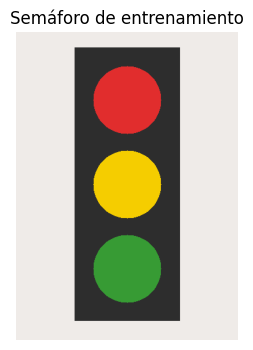

ROJO: brillo=225
AMARILLO: brillo=245
VERDE: brillo=155


In [2]:
imagen = cv2.imread(str(RECURSOS / 'semaforo.png'))
mostrar(imagen, 'Semáforo de entrenamiento')
# Coordenadas centrales conocidas en este ejemplo controlado.
luces = {'ROJO': (180, 110), 'AMARILLO': (180, 247), 'VERDE': (180, 384)}
hsv = cv2.cvtColor(imagen, cv2.COLOR_BGR2HSV)
for nombre, (x, y) in luces.items():
    # Canal V en HSV: brillo, de 0 (oscuro) a 255 (muy brillante).
    brillo = int(hsv[y, x, 2])
    print(f'{nombre}: brillo={brillo}')

### Explicación
En este dibujo las tres luces están coloreadas; **brillo por sí solo no determina un estado real**. Por ello, este ejercicio sirve para leer regiones; para detectar una luz encendida en un dispositivo real harían falta imágenes con luces apagadas y encendidas y calibración.

ROJO: H=0, S=204, V=225
AMARILLO: H=25, S=255, V=245
VERDE: H=59, S=169, V=155


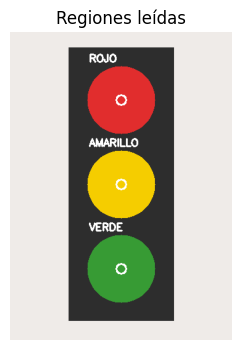

True

In [3]:
# Reconocemos qué color hay en el centro de cada región.
for nombre, (x, y) in luces.items():
    h, s, v = map(int, hsv[y, x])
    print(f'{nombre}: H={h}, S={s}, V={v}')

# Marcamos los puntos observados.
salida = imagen.copy()
for nombre, (x, y) in luces.items():
    cv2.circle(salida, (x, y), 8, (255, 255, 255), 2)
    cv2.putText(salida, nombre, (x-52, y-62), cv2.FONT_HERSHEY_SIMPLEX,.55,(255,255,255),2)
mostrar(salida, 'Regiones leídas')
cv2.imwrite(str(SALIDAS / 'semaforo_marcado.png'), salida)

**Reto guiado:** cambia la posición de uno de los puntos y verifica cómo varían sus canales. **Preguntas:** ¿qué pasa si se desplaza la cámara? ¿En qué momento haría falta detectar automáticamente la posición de las luces?

<div style="background-color:#FFF0A8;color:#463600;border-left:7px solid #D6A400;padding:14px 18px;border-radius:9px;margin:10px 0 16px"><strong>🟨 INICIO DEL DESARROLLO DE LA ACTIVIDAD</strong><br>Desde aquí se realiza el reto y sus comprobaciones. Se conserva el enunciado original y el código se ejecuta en orden.</div>

### Respuestas cortas

**¿Qué pasa al mover el punto o la cámara?** Cambia el color muestreado y la lectura puede ser incorrecta.  
**¿Cuándo detectar automáticamente la posición?** Cuando el semáforo no tiene la misma posición o escala en cada foto.

## Ejecución del reto del estudiante (actividad resuelta)

rojo píxeles detectados: 25940
amarillo píxeles detectados: 27078
verde píxeles detectados: 26788


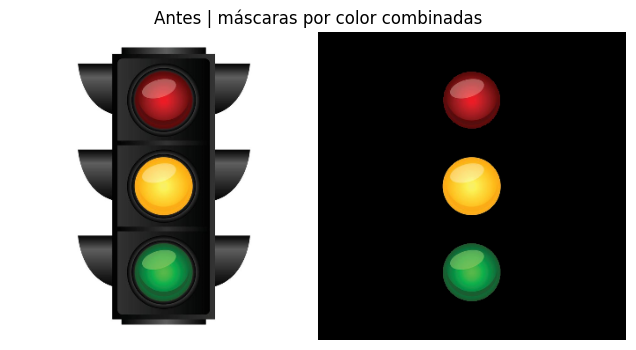

In [4]:
# Actividad del estudiante: sustituimos la imagen de prueba con una segunda del taller.
archivo = Path('..')/'00_Imagenes_Adicionales'/'SEMAFORO2.jpg'
prueba = cv2.imread(str(archivo))
assert prueba is not None, 'Falta la imagen SEMAFORO2.jpg original del taller'
hsv_prueba=cv2.cvtColor(prueba,cv2.COLOR_BGR2HSV)
rangos={
 'rojo':[(np.array([0,90,75]),np.array([10,255,255])),(np.array([170,90,75]),np.array([179,255,255]))],
 'amarillo':[(np.array([17,85,75]),np.array([37,255,255]))],
 'verde':[(np.array([35,70,65]),np.array([90,255,255]))]
}
color_map = {'rojo':(0,0,220),'amarillo':(0,200,240),'verde':(0,210,70)}
mascara_total=np.zeros(hsv_prueba.shape[:2],dtype=np.uint8)
for nombre, intervalos in rangos.items():
    marcadores=np.zeros_like(mascara_total)
    for bajo,alto in intervalos:marcadores=cv2.bitwise_or(marcadores,cv2.inRange(hsv_prueba,bajo,alto))
    print(nombre,'píxeles detectados:',int(np.count_nonzero(marcadores)))
    mascara_total=cv2.bitwise_or(mascara_total,marcadores)
segmentada=cv2.bitwise_and(prueba,prueba,mask=mascara_total)
comparacion=np.hstack([cv2.resize(prueba,(350,350)),cv2.resize(segmentada,(350,350))])
cv2.imwrite(str(SALIDAS/'05_semaforo_antes_despues.png'),comparacion)
mostrar(comparacion,'Antes | máscaras por color combinadas')

### Conclusión y evaluación

La sustitución de imagen exige analizar la iluminación. Los píxeles detectados no prueban que una luz esté encendida en un semáforo real; es segmentación de color en una fotografía.

**Evidencia:** ejecutar todas las celdas; las imágenes guardadas en `resultados/` muestran el procesamiento. La captura del cuaderno abierto corresponde al estudiante una vez ejecutado en su máquina.